# 4. Support Vector Machine (SVM) — Football xG Prediction

**IT461 — Practical Machine Learning | Group 10 | Member 4**

The goal is to predict whether a non-penalty shot becomes a goal (`1`) or not (`0`). The model's estimated probability of a goal is its **expected goals (xG)** value.

This notebook compares SVM models using two feature sets:
- **Location-only:** shot `distance` and `angle`.
- **Context-aware:** distance and angle, plus six features describing how the shot was taken.

We compare three SVM kernels, tune their settings with cross-validation, and evaluate the predicted goal probabilities.

**To run:** Execute the notebook from top to bottom. It uses the prepared dataset, shared train/test split, and preprocessing code in the repository. In a fresh Colab session, upload the repository ZIP when prompted. No other notebook needs to be run first.

## 4.1 Setup

First, locate the project folder and import the libraries. If the repository is not available in Colab, the notebook asks for its ZIP file. This lets the notebook use the same prepared data and preprocessing as the other models.

In [1]:
from pathlib import Path
import sys
import zipfile

# Find the repository locally before asking for a ZIP upload.
project_root = Path.cwd()
if not (project_root / "data/processed/modeling_dataset.csv").exists():
    if (project_root.parent / "data/processed/modeling_dataset.csv").exists():
        project_root = project_root.parent
    else:
        # Fresh Colab runtime: upload the repository ZIP.
        from google.colab import files
        print("Upload the IT461 project repository ZIP:")
        uploaded = files.upload()
        zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
        with zipfile.ZipFile(zip_name) as archive:
            archive.extractall(Path.cwd())
        project_root = next(
            path for path in Path.cwd().iterdir()
            if path.is_dir() and (path / "data/processed/modeling_dataset.csv").exists()
        )

sys.path.insert(0, str(project_root))
print("Project folder:", project_root)

Upload the IT461 project repository ZIP:


Saving IT461-football-shot-probability.zip to IT461-football-shot-probability.zip
Project folder: /content/IT461-football-shot-probability


In [2]:
import time
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, log_loss, brier_score_loss,
    average_precision_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, classification_report,
)

from src.preprocessing import (
    LOCATION_FEATURES, CONTEXT_FEATURES,
    make_location_preprocessor, make_context_preprocessor,
)

print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("Libraries and shared preprocessing loaded.")

Python: 3.13.18 | scikit-learn: 1.6.1
Libraries and shared preprocessing loaded.


## 4.2 Load the dataset

The exported `modeling_dataset.csv` is intentionally **unscaled and unencoded**. It contains the engineered features, but scaling and encoding must be fitted on training data only to avoid data leakage.

`model_split.csv` contains the shared train/test assignments. We match the files by shot ID and match ID, then check that no match appears in both sets.

In [3]:
data = pd.read_csv(project_root / "data/processed/modeling_dataset.csv")
splits = pd.read_csv(project_root / "data/processed/model_split.csv")

# Match split assignments by IDs, not by row order.
assert data["id"].is_unique and splits["id"].is_unique
shots = data.merge(splits, on=["id", "match_id"], validate="one_to_one")
assert len(shots) == len(data) == len(splits)
assert set(shots["split"]) == {"train", "test"}
assert set(shots["goal"].unique()) == {0, 1}
assert shots[CONTEXT_FEATURES].notna().all().all()

train = shots[shots["split"] == "train"].reset_index(drop=True)
test = shots[shots["split"] == "test"].reset_index(drop=True)

# Keep all shots from a match in the same partition.
assert set(train["match_id"]).isdisjoint(set(test["match_id"]))
print("Total shots:", len(shots), "| Total matches:", shots["match_id"].nunique())
print("Training:", len(train), "shots |", train["match_id"].nunique(), "matches")
print("Testing: ", len(test), "shots |", test["match_id"].nunique(), "matches")
print("Match overlap: 0")

Total shots: 12374 | Total matches: 500
Training: 9900 shots | 400 matches
Testing:  2474 shots | 100 matches
Match overlap: 0


In [4]:
# Check class balance in both partitions.
class_counts = shots.groupby("split")["goal"].agg(
    shots="count", goals="sum", goal_rate="mean"
)
class_counts["non_goals"] = class_counts["shots"] - class_counts["goals"]
display(class_counts[["shots", "non_goals", "goals", "goal_rate"]].round(4))

,shots,non_goals,goals,goal_rate
split,,,,
test,2474,2197,277,0.1120
train,9900,8794,1106,0.1117


## 4.3 Features and cross-validation

SVM learns a boundary between the goal and non-goal classes. We compare a model using just shot location with one using all eight features.

The preprocessing pipeline scales numeric features and encodes categorical features. Because it is inside the model pipeline, it is fitted again within each training fold.

We use **3-fold `StratifiedGroupKFold`**, grouping shots by `match_id`. Both feature sets use the same folds, and test matches are excluded from cross-validation.

In [5]:
y_train = train["goal"]
y_test = test["goal"]

X_train_location = train[LOCATION_FEATURES]
X_test_location = test[LOCATION_FEATURES]
X_train_context = train[CONTEXT_FEATURES]
X_test_context = test[CONTEXT_FEATURES]

# Reuse these folds for both SVM experiments.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train_location, y_train, groups=train["match_id"]))

for number, (train_idx, val_idx) in enumerate(cv_folds, 1):
    train_matches = set(train.loc[train_idx, "match_id"])
    val_matches = set(train.loc[val_idx, "match_id"])
    assert train_matches.isdisjoint(val_matches)
    print(f"Fold {number}: {len(train_idx)} training shots, {len(val_idx)} validation shots")

Fold 1: 6639 training shots, 3261 validation shots
Fold 2: 6562 training shots, 3338 validation shots
Fold 3: 6599 training shots, 3301 validation shots


## 4.4 Kernel comparison and hyperparameter tuning

We compare three SVM kernels:

- **Linear:** a straight decision boundary.
- **RBF:** a flexible nonlinear boundary.
- **Polynomial:** a boundary based on polynomial relationships (`coef0=1` allows lower-degree terms).

`GridSearchCV` tests combinations of **`C`** (regularization), **`gamma`** (influence of points in nonlinear kernels), and **`degree`** (polynomial complexity).

Only about **11% of shots are goals**. We therefore test both regular and **balanced class weights**, which give the rarer goal class more importance during training. This does not change the original class distribution.

The best settings are chosen by **mean ROC AUC across three match-separated validation folds**. The test set is not used for tuning.

In [6]:
# Compare the usual SVM against one that gives more weight to rare goals.
parameter_grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10],
     "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10],
     "svm__gamma": ["scale", 0.1], "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["poly"], "svm__C": [0.1],
     "svm__gamma": ["scale"], "svm__degree": [2, 3],
     "svm__coef0": [1],
     "svm__class_weight": [None, "balanced"]},
]

print("Grid candidates per feature set: 22 (each tested across 3 folds)")

Grid candidates per feature set: 22 (each tested across 3 folds)


### 4.4.1 Location-only SVM

Train an SVM using only `distance` and `angle`. Grid search tests the kernel settings on the three training folds and reports the best result.

In [7]:
location_pipeline = Pipeline([
    ("preprocessing", make_location_preprocessor()),
    ("svm", SVC()),
])

location_search = GridSearchCV(
    location_pipeline, parameter_grid, scoring="roc_auc",
    cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
location_search.fit(X_train_location, y_train)
location_seconds = time.perf_counter() - start

print("Location-only best parameters:", location_search.best_params_)
print("Location-only best CV ROC AUC:", round(location_search.best_score_, 4))
print(f"Grid search time: {location_seconds:.1f} seconds")

Location-only best parameters: {'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__kernel': 'linear'}
Location-only best CV ROC AUC: 0.7335
Grid search time: 145.4 seconds


In [8]:
location_cv = pd.DataFrame(location_search.cv_results_)
location_settings = location_cv[[
    "param_svm__kernel", "param_svm__C", "param_svm__gamma",
    "param_svm__degree", "param_svm__coef0", "param_svm__class_weight",
    "mean_test_score", "std_test_score",
]].copy()
location_settings.columns = [
    "Kernel", "C", "Gamma", "Degree", "Coef0", "Class weight", "Mean CV AUC", "CV std. dev."
]
display(location_settings.fillna("-").sort_values("Mean CV AUC", ascending=False).round(4))

,Kernel,C,Gamma,Degree,Coef0,Class weight,Mean CV AUC,CV std. dev.
1,linear,0.1,-,-,-,balanced,0.7335,0.0054
3,linear,1.0,-,-,-,balanced,0.7332,0.0056
5,linear,10.0,-,-,-,balanced,0.7332,0.0056
0,linear,0.1,-,-,-,-,0.7313,0.0034
9,rbf,0.1,0.1,-,-,balanced,0.7306,0.0038
21,poly,0.1,scale,3.0,1.0,balanced,0.7305,0.0034
20,poly,0.1,scale,2.0,1.0,balanced,0.7303,0.0058
13,rbf,1.0,0.1,-,-,balanced,0.7277,0.0032
17,rbf,10.0,0.1,-,-,balanced,0.7263,0.0026
12,rbf,1.0,scale,-,-,balanced,0.7204,0.0101


### 4.4.2 Context-aware SVM

Repeat the same experiment using all eight features and the **same validation folds**, so the comparison is fair.

In [9]:
context_pipeline = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("svm", SVC()),
])

context_search = GridSearchCV(
    context_pipeline, parameter_grid, scoring="roc_auc",
    cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
context_search.fit(X_train_context, y_train)
context_seconds = time.perf_counter() - start

print("Context-aware best parameters:", context_search.best_params_)
print("Context-aware best CV ROC AUC:", round(context_search.best_score_, 4))
print(f"Grid search time: {context_seconds:.1f} seconds")

Context-aware best parameters: {'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__kernel': 'linear'}
Context-aware best CV ROC AUC: 0.7723
Grid search time: 187.1 seconds


In [10]:
context_cv = pd.DataFrame(context_search.cv_results_)
context_settings = context_cv[[
    "param_svm__kernel", "param_svm__C", "param_svm__gamma",
    "param_svm__degree", "param_svm__coef0", "param_svm__class_weight",
    "mean_test_score", "std_test_score",
]].copy()
context_settings.columns = [
    "Kernel", "C", "Gamma", "Degree", "Coef0", "Class weight", "Mean CV AUC", "CV std. dev."
]
display(context_settings.fillna("-").sort_values("Mean CV AUC", ascending=False).round(4))

,Kernel,C,Gamma,Degree,Coef0,Class weight,Mean CV AUC,CV std. dev.
5,linear,10.0,-,-,-,balanced,0.7723,0.0040
3,linear,1.0,-,-,-,balanced,0.7722,0.0040
20,poly,0.1,scale,2.0,1.0,balanced,0.7718,0.0022
1,linear,0.1,-,-,-,balanced,0.7703,0.0025
9,rbf,0.1,0.1,-,-,balanced,0.7666,0.0033
21,poly,0.1,scale,3.0,1.0,balanced,0.7663,0.0014
8,rbf,0.1,scale,-,-,balanced,0.7647,0.0037
13,rbf,1.0,0.1,-,-,balanced,0.7638,0.0031
12,rbf,1.0,scale,-,-,balanced,0.7542,0.0032
17,rbf,10.0,0.1,-,-,balanced,0.7407,0.0054


### 4.4.3 Compare kernels and class weights

The table and chart compare the strongest validation ROC AUC for each kernel. The second table shows whether balancing the classes helped during tuning. These results use training folds only.

,Feature set,Kernel,Best CV ROC AUC
0,Location-only,linear,0.7335
1,Location-only,rbf,0.7306
2,Location-only,poly,0.7305
3,Context-aware,linear,0.7723
4,Context-aware,rbf,0.7666
5,Context-aware,poly,0.7718


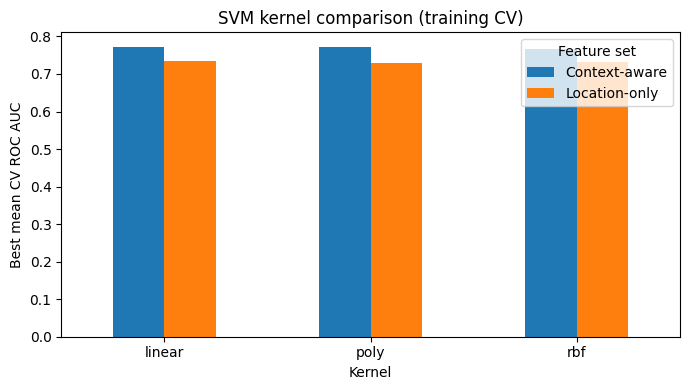

In [11]:
kernel_results = []
for feature_set, search in [("Location-only", location_search),
                            ("Context-aware", context_search)]:
    cv_results = pd.DataFrame(search.cv_results_)
    for kernel in ["linear", "rbf", "poly"]:
        selected = cv_results[cv_results["param_svm__kernel"] == kernel]
        kernel_results.append({
            "Feature set": feature_set,
            "Kernel": kernel,
            "Best CV ROC AUC": selected["mean_test_score"].max(),
        })

kernel_table = pd.DataFrame(kernel_results)
display(kernel_table.round(4))

kernel_plot = kernel_table.pivot(index="Kernel", columns="Feature set", values="Best CV ROC AUC")
kernel_plot.plot(kind="bar", figsize=(7, 4), rot=0)
plt.ylabel("Best mean CV ROC AUC")
plt.title("SVM kernel comparison (training CV)")
plt.tight_layout()
plt.show()

In [12]:
weight_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    results = pd.DataFrame(search.cv_results_)
    results["Class weight"] = results["param_svm__class_weight"].fillna("None")
    for weight in ["None", "balanced"]:
        selected = results[results["Class weight"] == weight]
        weight_rows.append({
            "Feature set": name,
            "Class weight": weight,
            "Best mean CV ROC AUC": selected["mean_test_score"].max(),
        })

display(pd.DataFrame(weight_rows).round(4))

,Feature set,Class weight,Best mean CV ROC AUC
0,Location-only,None,0.7313
1,Location-only,balanced,0.7335
2,Context-aware,None,0.6556
3,Context-aware,balanced,0.7723


## 4.5 Estimate xG probabilities

A regular SVM produces a decision score rather than a scoring probability. We use **sigmoid calibration** to turn those scores into xG values between 0 and 1.

`CalibratedClassifierCV` uses match-separated training folds for calibration. We use this instead of `SVC(probability=True)` so that the calibration folds also respect match boundaries. The test set remains untouched.

In [13]:
location_model = CalibratedClassifierCV(
    estimator=location_search.best_estimator_, method="sigmoid",
    cv=cv_folds, ensemble=False
)
context_model = CalibratedClassifierCV(
    estimator=context_search.best_estimator_, method="sigmoid",
    cv=cv_folds, ensemble=False
)

location_model.fit(X_train_location, y_train)
context_model.fit(X_train_context, y_train)
print("Both selected SVMs fitted with match-separated sigmoid calibration.")

Both selected SVMs fitted with match-separated sigmoid calibration.


In [14]:
# Column 1 gives P(goal = 1), which is our xG estimate.
location_xg = location_model.predict_proba(X_test_location)[:, 1]
context_xg = context_model.predict_proba(X_test_context)[:, 1]

example_predictions = test[["id", "goal"]].head(5).copy()
example_predictions["Location xG"] = location_xg[:5]
example_predictions["Context xG"] = context_xg[:5]
display(example_predictions.round(4))

,id,goal,Location xG,Context xG
0,c5341577-e1ca-4742-98fb-dc745cbbe103,0,0.0995,0.1145
1,1aedaf9e-bc12-4d0a-953d-bd0f7db3688a,0,0.0777,0.0854
2,96b28bfc-d174-4b38-86cf-5a43cda4a14f,0,0.1028,0.1081
3,b9ca5464-1f5a-401b-a31d-8101bd61072a,0,0.0628,0.0799
4,75bdc651-c041-4021-b201-cb9eb8b97837,1,0.5195,0.9422


### 4.5.1 Check predicted probabilities

The model should assign different xG values to shots with different scoring chances. The summary below helps check whether predictions vary meaningfully instead of staying near the average goal rate.

In [15]:
probability_summary = pd.DataFrame({
    "Feature set": ["Location-only", "Context-aware"],
    "Mean xG": [location_xg.mean(), context_xg.mean()],
    "Std. dev.": [location_xg.std(), context_xg.std()],
    "Min xG": [location_xg.min(), context_xg.min()],
    "Median xG": [np.median(location_xg), np.median(context_xg)],
    "Max xG": [location_xg.max(), context_xg.max()],
})
display(probability_summary.round(4))

,Feature set,Mean xG,Std. dev.,Min xG,Median xG,Max xG
0,Location-only,0.1119,0.0845,0.0004,0.0881,0.6764
1,Context-aware,0.1119,0.1194,0.0008,0.0756,0.9871


## 4.6 Preliminary evaluation

Most shots are non-goals, so **accuracy alone is misleading**. We report precision, recall and F1 for classification, ROC AUC and average precision for ranking, and **log loss and Brier score** for probability quality.

We also compare against a simple baseline that gives every shot the training set's average goal probability. Classification metrics use a threshold of **0.5**; low recall at this threshold does not necessarily mean the xG probabilities are unhelpful.

In [16]:
# The baseline predicts the same training goal rate for every shot.
training_goal_rate = y_train.mean()
baseline_xg = np.full(len(test), training_goal_rate)

def evaluate_probabilities(name, probabilities):
    labels = (probabilities >= 0.5).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, labels),
        "Precision": precision_score(y_test, labels, zero_division=0),
        "Recall": recall_score(y_test, labels, zero_division=0),
        "F1": f1_score(y_test, labels, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(y_test, probabilities),
        "Log loss": log_loss(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
    }

metrics = pd.DataFrame([
    evaluate_probabilities("Training-rate baseline", baseline_xg),
    evaluate_probabilities("Location-only SVM", location_xg),
    evaluate_probabilities("Context-aware SVM", context_xg),
])
display(metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Average precision,Log loss,Brier score
0,Training-rate baseline,0.8880,0.0000,0.0000,0.0000,0.5000,0.1120,0.3506,0.0994
1,Location-only SVM,0.8909,1.0000,0.0253,0.0493,0.7529,0.3371,0.3072,0.0888
2,Context-aware SVM,0.8989,0.7755,0.1372,0.2331,0.7969,0.4269,0.2847,0.0815


### 4.6.1 ROC curve

The ROC curve shows how well each model separates goals from non-goals across different thresholds. A higher ROC AUC indicates better ranking.

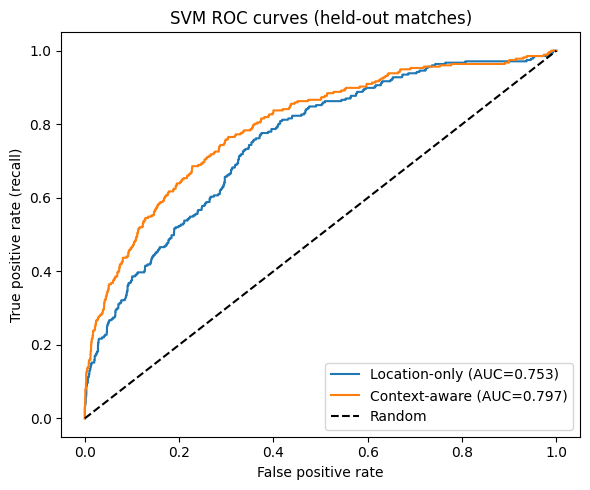

In [17]:
plt.figure(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("SVM ROC curves (held-out matches)")
plt.legend()
plt.tight_layout()
plt.show()

### 4.6.2 Precision–recall curve

Goals are uncommon, so a precision–recall curve is useful alongside ROC AUC. Higher curves indicate better precision at a given recall. The dashed line shows the goal rate in the test set.

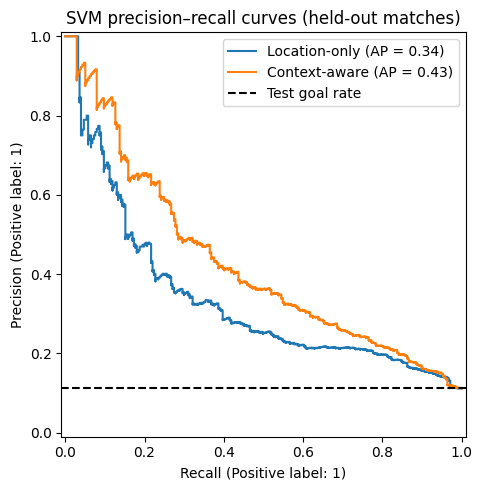

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=label, ax=ax)
ax.axhline(y_test.mean(), color="black", linestyle="--", label="Test goal rate")
ax.set_title("SVM precision–recall curves (held-out matches)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.6.3 Calibration curve

This plot compares predicted xG with actual goal rates. If shots predicted at about 0.20 xG score around 20% of the time, the probabilities are well calibrated in that range. The diagonal represents ideal calibration.

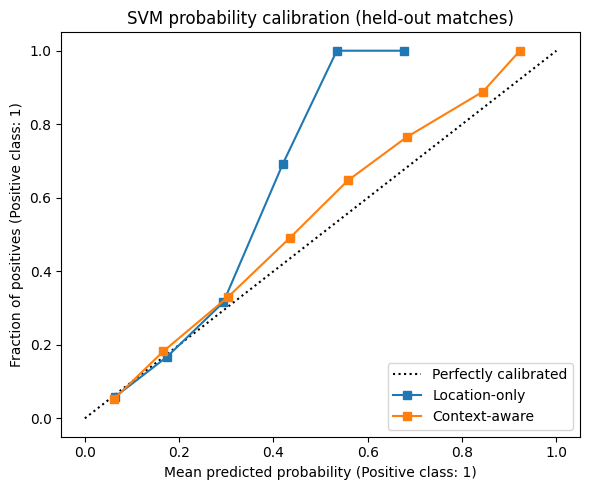

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, location_xg, n_bins=8,
                                    name="Location-only", ax=ax)
CalibrationDisplay.from_predictions(y_test, context_xg, n_bins=8,
                                    name="Context-aware", ax=ax)
ax.set_title("SVM probability calibration (held-out matches)")
plt.tight_layout()
plt.show()

### 4.6.4 Confusion matrix

The confusion matrix shows correct and incorrect classifications for the context-aware model at a **0.5 threshold**. Because goals are rare, many shots may be predicted as non-goals even when their xG probabilities are useful.

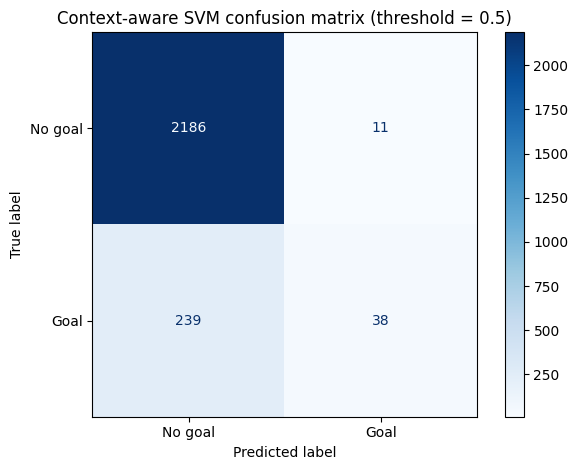

In [20]:
context_labels = (context_xg >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, context_labels, display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title("Context-aware SVM confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

### 4.6.5 Per-class classification results

This report shows precision, recall and F1 separately for **goals** and **non-goals** using the usual 0.5 threshold. A low goal recall does not by itself mean xG estimates are poor.

In [21]:
for name, probabilities in [("Location-only", location_xg),
                            ("Context-aware", context_xg)]:
    print(f"\n{name} SVM (threshold = 0.5)")
    labels = (probabilities >= 0.5).astype(int)
    print(classification_report(y_test, labels,
          target_names=["No goal", "Goal"], digits=3, zero_division=0))


Location-only SVM (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.891     1.000     0.942      2197
        Goal      1.000     0.025     0.049       277

    accuracy                          0.891      2474
   macro avg      0.945     0.513     0.496      2474
weighted avg      0.903     0.891     0.842      2474


Context-aware SVM (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.901     0.995     0.946      2197
        Goal      0.776     0.137     0.233       277

    accuracy                          0.899      2474
   macro avg      0.838     0.566     0.590      2474
weighted avg      0.887     0.899     0.866      2474



## 4.7 Findings and best SVM

We select the **best SVM by cross-validation ROC AUC** (the criterion used during tuning). Then we compare its held-out results with the other feature set and the training-rate baseline.

ROC AUC and average precision measure how well shots are ranked. Log loss and Brier score measure the accuracy of **xG probabilities**. These measures may favor different models.

In [22]:
# Select the overall best SVM using validation performance, not the test set.
if location_search.best_score_ >= context_search.best_score_:
    best_name, best_search = "Location-only", location_search
else:
    best_name, best_search = "Context-aware", context_search

print(f"Best SVM by cross-validation ROC AUC: {best_name}")
print("Best settings:", best_search.best_params_)
print(f"Mean CV ROC AUC: {best_search.best_score_:.4f}")

location_row = metrics.loc[metrics["Model"] == "Location-only SVM"].iloc[0]
context_row = metrics.loc[metrics["Model"] == "Context-aware SVM"].iloc[0]
baseline_row = metrics.loc[metrics["Model"] == "Training-rate baseline"].iloc[0]

print("\nTest-set results (location → context):")
for metric in ["ROC AUC", "Average precision", "Log loss", "Brier score", "Recall"]:
    print(f"{metric}: {location_row[metric]:.4f} → {context_row[metric]:.4f}")
print(f"Training-rate baseline: log loss = {baseline_row['Log loss']:.4f}, "
      f"Brier score = {baseline_row['Brier score']:.4f}")

print("\nInterpretation:")
if context_row["ROC AUC"] > location_row["ROC AUC"]:
    print("Context features improved the ranking of scoring chances on held-out matches.")
else:
    print("Context features did not improve ROC AUC on held-out matches.")
if (context_row["Log loss"] < location_row["Log loss"] and
        context_row["Brier score"] < location_row["Brier score"]):
    print("Context features also improved both probability-error measures.")
else:
    print("Context features did not improve both probability-error measures.")
print("Classification recall at 0.5 should be interpreted cautiously for rare goals.")

Best SVM by cross-validation ROC AUC: Context-aware
Best settings: {'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__kernel': 'linear'}
Mean CV ROC AUC: 0.7723

Test-set results (location → context):
ROC AUC: 0.7529 → 0.7969
Average precision: 0.3371 → 0.4269
Log loss: 0.3072 → 0.2847
Brier score: 0.0888 → 0.0815
Recall: 0.0253 → 0.1372
Training-rate baseline: log loss = 0.3506, Brier score = 0.0994

Interpretation:
Context features improved the ranking of scoring chances on held-out matches.
Context features also improved both probability-error measures.
Classification recall at 0.5 should be interpreted cautiously for rare goals.


## 4.8 Save results for model comparison

Save the test-shot IDs, true labels and both xG predictions in `svm_predictions.csv`. We also save the metrics and fitted models, so the SVM results can be compared with Logistic Regression on the **same test shots**.

In [23]:
results_dir = project_root / "results"
models_dir = project_root / "models"
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)

predictions = test[["id", "match_id", "goal"]].copy()
predictions["svm_location_xg"] = location_xg
predictions["svm_context_xg"] = context_xg
predictions.to_csv(results_dir / "svm_predictions.csv", index=False)
metrics.to_csv(results_dir / "svm_metrics.csv", index=False)

joblib.dump(location_model, models_dir / "svm_location.joblib")
joblib.dump(context_model, models_dir / "svm_context.joblib")

print("Saved:")
print("- results/svm_predictions.csv")
print("- results/svm_metrics.csv")
print("- models/svm_location.joblib")
print("- models/svm_context.joblib")
print("Test-shot prediction rows:", len(predictions))

Saved:
- results/svm_predictions.csv
- results/svm_metrics.csv
- models/svm_location.joblib
- models/svm_context.joblib
Test-shot prediction rows: 2474


## 4.9 Checkpoint summary

This notebook trains SVMs with linear, RBF and polynomial kernels using both location-only and context-aware features. It compares class weights, tunes parameters with match-separated cross-validation, and calibrates SVM scores into xG probabilities.

The tables and figures show the actual results, including the best SVM selected by **validation ROC AUC** in Section 4.7. The exported predictions can be compared with Logistic Regression on the same test shots.

For submission, run every cell in order in Google Colab and save the notebook with its outputs.